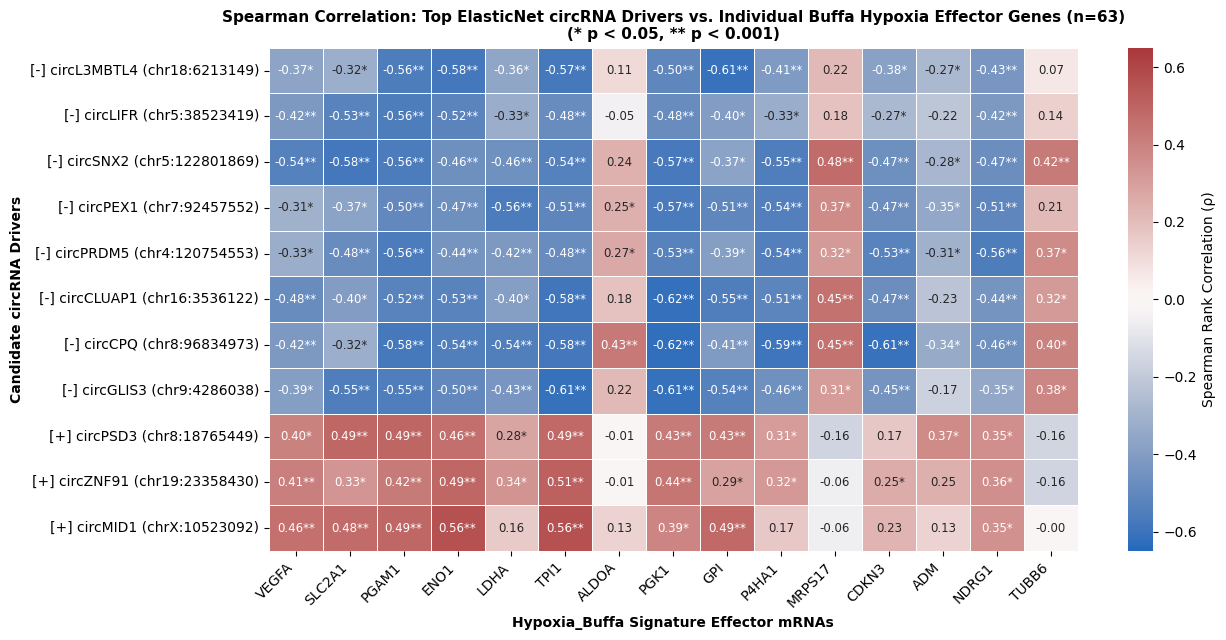

=== Circular vs. Linear Host mRNA Independence Check (Spearman ρ) ===
              circRNA_id Host_Gene  rho(circ, Hypoxia)  rho(circ, Linear_Host)  rho(Linear_Host, Hypoxia)  Partial_rho(circ|Host)
   chr18:6213149|6312056   L3MBTL4              -0.573                   0.150                      0.020                  -0.583
  chr5:38523419|38530666      LIFR              -0.507                   0.377                     -0.161                  -0.488
chr5:122801869|122803613      SNX2              -0.544                  -0.382                      0.388                  -0.465
  chr7:92457552|92492286      PEX1              -0.585                  -0.255                      0.284                  -0.553
chr4:120754553|120811449     PRDM5              -0.545                  -0.059                      0.031                  -0.545
   chr16:3536122|3536994    CLUAP1              -0.559                  -0.151                      0.118                  -0.552
  chr8:96834973|9688

In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# 1. Load processed matrices & cached gene names
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "Scripts" else Path.cwd()
PROCESSED_DIR = PROJECT_ROOT / "Processed"

X_circ_logcpm = pd.read_csv(PROCESSED_DIR / "GSE236932_circRNA_log2cpm.csv", index_col=0)
mrna_log2 = pd.read_csv(PROCESSED_DIR / "GSE236932_mRNA_log2.csv", index_col=0)
scores_df = pd.read_csv(PROCESSED_DIR / "GSE236932_target_scores.csv", index_col=0)
summary_circ = pd.read_csv(PROCESSED_DIR / "GSE236932_top_drivers_Hypoxia_Buffa.csv", index_col=0)

with open(PROCESSED_DIR / "signatures.json") as f:
    signatures = json.load(f)
with open(PROCESSED_DIR / "coord_to_gene_cache.json") as f:
    gene_cache = json.load(f)

sample_cols = scores_df.index.tolist()
X_circ_logcpm = X_circ_logcpm[sample_cols]
mrna_log2 = mrna_log2[sample_cols]

# 2. Select Top 8 Negative Drivers (Freq >= 0.6) + Top 3 Positive Drivers
top_neg_ids = summary_circ[summary_circ["Selection_Freq"] >= 0.6].index.tolist()
top_pos_ids = summary_circ[summary_circ["Mean_Coef"] > 0].index.tolist()
selected_circ_ids = top_neg_ids + top_pos_ids

# Build readable labels: e.g. "circLIFR (chr5:38523419)"
circ_labels = []
for cid in selected_circ_ids:
    host = gene_cache.get(cid, "Unknown").split(",")[-1]
    short_coord = cid.split("|")[0]
    direction = "[+]" if summary_circ.loc[cid, "Mean_Coef"] > 0 else "[-]"
    circ_labels.append(f"{direction} circ{host} ({short_coord})")

# 3. Compute Spearman rank correlation matrix: Selected circRNAs vs. 15 Hypoxia mRNAs
hypoxia_genes = [g for g in signatures["Hypoxia_Buffa"] if g in mrna_log2.index]
rho_matrix = pd.DataFrame(index=circ_labels, columns=hypoxia_genes, dtype=float)
pval_matrix = pd.DataFrame(index=circ_labels, columns=hypoxia_genes, dtype=float)

for cid, label in zip(selected_circ_ids, circ_labels):
    c_expr = X_circ_logcpm.loc[cid]
    for h_gene in hypoxia_genes:
        m_expr = mrna_log2.loc[h_gene]
        rho, pval = spearmanr(c_expr, m_expr)
        rho_matrix.loc[label, h_gene] = rho
        pval_matrix.loc[label, h_gene] = pval

# Quick patch to update coord_to_gene_cache.json with the 3 positive drivers
gene_cache.update({
    "chr8:18765449|18940293": "PSD3",
    "chr19:23358430|23362739": "ZNF91",
    "chrX:10523092|10567603": "MID1"
})
with open(PROCESSED_DIR / "coord_to_gene_cache.json", "w") as f:
    json.dump(gene_cache, f, indent=2)

# 4. Plot Spearman Correlation Heatmap with significance stars
plt.figure(figsize=(13, 6.5))
annot_matrix = rho_matrix.round(2).astype(str)
for r in range(rho_matrix.shape[0]):
    for c in range(rho_matrix.shape[1]):
        p = pval_matrix.iloc[r, c]
        val = f"{rho_matrix.iloc[r, c]:.2f}"
        if p < 0.001:
            annot_matrix.iloc[r, c] = val + "**"
        elif p < 0.05:
            annot_matrix.iloc[r, c] = val + "*"
        else:
            annot_matrix.iloc[r, c] = val

sns.heatmap(
    rho_matrix, cmap="vlag", center=0, vmin=-0.65, vmax=0.65,
    annot=annot_matrix, fmt="", cbar_kws={"label": "Spearman Rank Correlation (ρ)"},
    linewidths=0.5, annot_kws={"size": 8.5}
)
plt.title("Spearman Correlation: Top ElasticNet circRNA Drivers vs. Individual Buffa Hypoxia Effector Genes (n=63)\n(* p < 0.05, ** p < 0.001)", fontweight="bold", fontsize=11)
plt.xlabel("Hypoxia_Buffa Signature Effector mRNAs", fontweight="bold")
plt.ylabel("Candidate circRNA Drivers", fontweight="bold")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(PROCESSED_DIR / "GSE236932_circRNA_vs_Hypoxia_Genes_Heatmap.png", dpi=300)
plt.show()

# 5. Host-Gene Independence Check (Circular vs. Linear Host mRNA)
print("=== Circular vs. Linear Host mRNA Independence Check (Spearman ρ) ===")
check_records = []
for cid in top_neg_ids + top_pos_ids:
    hosts = [h.strip() for h in gene_cache.get(cid, "").split(",") if h.strip() in mrna_log2.index]
    c_expr = X_circ_logcpm.loc[cid]
    rho_circ_hyp, p_circ_hyp = spearmanr(c_expr, scores_df["Hypoxia_Buffa"])
    
    if hosts:
        host_sym = hosts[-1]
        h_expr = mrna_log2.loc[host_sym]
        rho_circ_host, _ = spearmanr(c_expr, h_expr)
        rho_host_hyp, _ = spearmanr(h_expr, scores_df["Hypoxia_Buffa"])
        
        # Partial Spearman correlation: circRNA vs Hypoxia controlling for linear Host mRNA
        p_rho = (rho_circ_hyp - rho_circ_host * rho_host_hyp) / (
            np.sqrt(1 - rho_circ_host**2) * np.sqrt(1 - rho_host_hyp**2)
        )
        check_records.append({
            "circRNA_id": cid,
            "Host_Gene": host_sym,
            "rho(circ, Hypoxia)": round(rho_circ_hyp, 3),
            "rho(circ, Linear_Host)": round(rho_circ_host, 3),
            "rho(Linear_Host, Hypoxia)": round(rho_host_hyp, 3),
            "Partial_rho(circ|Host)": round(p_rho, 3)
        })



indep_df = pd.DataFrame(check_records)
print(indep_df.to_string(index=False))
indep_df.to_csv(PROCESSED_DIR / "GSE236932_host_independence_check.csv", index=False)

In [3]:
print("pos", top_pos_ids)
print("neg", top_neg_ids)

pos ['chr8:18765449|18940293', 'chr19:23358430|23362739', 'chrX:10523092|10567603']
neg ['chr18:6213149|6312056', 'chr5:38523419|38530666', 'chr5:122801869|122803613', 'chr7:92457552|92492286', 'chr4:120754553|120811449', 'chr16:3536122|3536994', 'chr8:96834973|96880005', 'chr9:4286038|4286523']
